# Sense Clustering Exploration

Interactive development of `src/wsd/sense_clustering.py`.

Tests the clustering approach on 3 pilot words: **schlagen, Geist, spielen**

Goal: calibrate the distance threshold (0.14 / 0.16 / 0.18) before running all 90 words.

In [1]:
import sys
sys.path.insert(0, '../../')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import AgglomerativeClustering

from src.diachronic.io import load_senses
from src.wsd.embedder import Embedder
from src.wsd.embedding_strategies import embed_with_representation

matplotlib.rcParams['figure.dpi'] = 120

SENSES_PATH = Path('../../data/processed/germanet/senses_pilot.jsonl')
TEST_LEMMAS = ['schlagen', 'Geist', 'spielen', 'Berg', 'Kugel', 'Kopf', 'sprechen', 'tief', 'gehen', 'fassen']
# Calibrated for core_gloss (A) representation — distances range ~0.04–0.18.
# t=0.08 conservative, t=0.10 moderate (constrained=False for schlagen), t=0.12 aggressive.
THRESHOLDS = [0.08, 0.10, 0.12]

## 1. Load senses and embed

`load_senses()` reads the JSONL file and expands the `llm_examples` list into `llm_example_1..5` columns as expected by `embed_with_representation`.

In [2]:
senses_df = load_senses(SENSES_PATH, target_lemmas=TEST_LEMMAS)
available_lemmas = [l for l in TEST_LEMMAS if l in senses_df['lemma'].values]
print(f"Loaded {len(senses_df)} senses for {senses_df['lemma'].nunique()} words")
senses_df.groupby('lemma').size().rename('n_senses')

Loaded 92 senses for 10 words


lemma
Berg         2
Geist        6
Kopf         8
Kugel        3
fassen      12
gehen       19
schlagen    15
spielen     15
sprechen     6
tief         6
Name: n_senses, dtype: int64

## 1b. Gloss quality review

Side-by-side view of `baseline` (GermaNet input) vs `core_gloss` (LLM output) per lemma.

**What to look for:**
- Does the gloss capture the specific object/context from the baseline? (e.g. "Sahne", "Uhr", "Trommel")
- Are glosses for different senses of the same lemma distinguishable from each other?
- Flag: near-identical glosses across senses that have clearly different baselines

In [3]:
for lemma in available_lemmas:
    rows = senses_df[senses_df['lemma'] == lemma][['synset_id', 'baseline', 'core_gloss']].reset_index(drop=True)
    print(f"\n{'='*80}")
    print(f"{lemma}  ({len(rows)} senses)")
    print(f"{'='*80}")
    print(f"  {'#':<3}  {'synset_id':<10}  {'baseline':<42}  core_gloss")
    print(f"  {'-'*3}  {'-'*10}  {'-'*42}  {'-'*35}")
    for _, r in rows.iterrows():
        baseline_short = str(r['baseline'])[:40].replace('\n', ' ')
        print(f"  {_:<3}  {r['synset_id']:<10}  {baseline_short:<42}  {r['core_gloss']}")


schlagen  (15 senses)
  #    synset_id   baseline                                    core_gloss
  ---  ----------  ------------------------------------------  -----------------------------------
  0    s57717      mit Heftigkeit gegen etwas fallen ; Er i    Heftig gegen etwas fallen
  1    s52013      in Art, Wesen und/oder Aussehen einem an    in Art und Wesen einem anderen Familienmitglied ähnlich sein
  2    s56941      eine Schlägerei austragen ; Die Fans sch    jemandem Schläge versetzen oder sich prügeln
  3    s56959      durch einen Schlag irgendwohin befördern    etwas mit einem Schlag irgendwohin befördern
  4    s56972      Sie schlug mit dem Zirkel einen Kreis.|S    Mit einem Werkzeug oder Körperteil auf etwas einwirken
  5    s56930      jmdm./einem Tier einen Schlag/mehrere Sc    jmdm./einem Tier einen Schlag/mehrere Schläge versetzen
  6    s123462     Die Bäckerin hat die Sahne geschlagen. ;    Sahne durch kräftiges Rühren aufschlagen
  7    s56948      mit Hilfe eines

## 1b. Representation comparison

We compare three sense embedding representations to choose the best one for clustering:

| Name | Formula | Purpose |
|------|---------|---------|
| **Original** | 0.5 × `llm_definition` + 0.5 × avg(examples) | Current WSD production representation (54.8% accuracy) |
| **A** | `core_gloss` only | Minimal boilerplate — pure denotative label |
| **B** | 0.5 × `core_gloss` + 0.5 × avg(examples) | Clean definition + rich usage examples |

**Hypothesis**: `llm_definition` contains shared contrastive boilerplate ("Diese Bedeutung unterscheidet sich von...") that compresses all sense embeddings toward the same centroid, shrinking inter-sense distances to 0.13–0.21. `core_gloss` removes that noise. We expect A and B to show a wider distance range than Original.

Note: B uses the same α=0.5 as Original for now. We can tune α later if needed.

In [4]:
embedder = Embedder(model_name='intfloat/multilingual-e5-large', normalize=True)

def encode_passages(texts):
    return embedder.encode(['passage: ' + t for t in texts], show_progress=False)

# Original: llm_definition + examples weighted (current WSD production)
print("Encoding Original (llm_definition + examples)...")
embeddings_original = embed_with_representation(
    senses_df, embedder, representation='weighted',
    show_progress=True, passage_prefix='passage: ',
)

# A: core_gloss only
print("\nEncoding A (core_gloss only)...")
embeddings_A = encode_passages(senses_df['core_gloss'].fillna('').tolist())

# B: core_gloss + examples weighted (alpha=0.5)
print("\nEncoding B (core_gloss + examples)...")
gloss_embs = encode_passages(senses_df['core_gloss'].fillna('').tolist())
example_cols = [f'llm_example_{i}' for i in range(1, 6)]
example_embs_list = [encode_passages(senses_df[col].fillna('').tolist()) for col in example_cols]
avg_examples = np.mean(np.stack(example_embs_list, axis=0), axis=0)
combined = 0.5 * gloss_embs + 0.5 * avg_examples
norms = np.linalg.norm(combined, axis=1, keepdims=True)
embeddings_B = combined / np.where(norms == 0, 1, norms)

print(f"\nAll embeddings shape: {embeddings_original.shape}")

Encoding Original (llm_definition + examples)...


Batches:   0%|          | 0/3 [00:00<?, ?it/s]


Encoding A (core_gloss only)...

Encoding B (core_gloss + examples)...

All embeddings shape: (92, 1024)


## 2. Core clustering functions

Implemented in `src/wsd/sense_clustering.py`.

Algorithm: agglomerative clustering, average linkage, cosine distance (`1 - dot_product` for L2-normalized vectors). Cluster count is controlled by `threshold`; `min_clusters=2` is the only constraint — no upper bound. Sparse word-decade cells are filtered at analysis time.

In [17]:
def cosine_distance_matrix(embs: np.ndarray) -> np.ndarray:
    """Compute pairwise cosine distance matrix. Embeddings must be L2-normalized."""
    sim = embs @ embs.T
    sim = np.clip(sim, -1.0, 1.0)
    return 1.0 - sim


def cluster_senses_for_lemma(
    embs: np.ndarray,
    sense_ids: list,
    threshold: float,
    min_clusters: int = 2,
) -> dict:
    """Cluster senses for a single lemma.

    Returns dict mapping fine_sense_id -> coarse_cluster_index.
    No upper bound on cluster count — threshold determines granularity organically.
    min_clusters=2 only fires when the threshold collapses everything to 1 cluster.
    """
    n = len(sense_ids)

    if n == 1:
        return {sense_ids[0]: 0}

    dist_matrix = cosine_distance_matrix(embs)

    model = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=threshold,
        metric='precomputed',
        linkage='average',
    )
    labels = model.fit_predict(dist_matrix)
    n_clusters = len(set(labels))

    # Enforce minimum only — no upper bound
    if n_clusters < min_clusters <= n:
        model2 = AgglomerativeClustering(
            n_clusters=min_clusters,
            metric='precomputed',
            linkage='average',
        )
        labels = model2.fit_predict(dist_matrix)

    return {sid: int(lbl) for sid, lbl in zip(sense_ids, labels)}


print("Functions defined.")

Functions defined.


## 2b. Distance scale diagnostic

Before choosing thresholds, check the actual pairwise cosine distance distributions per lemma. This tells us whether the candidate thresholds (0.20–0.30) are even in the right range, or whether all senses are much closer to each other than expected.

In [18]:
repr_map = {
    'Original (llm_def+ex)': embeddings_original,
    'A (core_gloss only)':   embeddings_A,
    'B (core_gloss+ex)':     embeddings_B,
}

for repr_name, embs_all in repr_map.items():
    print(f"\n{'='*72}")
    print(f"Representation: {repr_name}")
    print(f"{'lemma':<12} {'n':>4} {'min':>8} {'mean':>8} {'max':>8} {'p25':>8} {'p50':>8} {'p75':>8}")
    print("-" * 72)
    for lemma in available_lemmas:
        mask = senses_df['lemma'] == lemma
        embs = embs_all[mask.values]
        dist = cosine_distance_matrix(embs)
        idx = np.triu_indices(len(embs), k=1)
        pw = dist[idx]
        print(f"{lemma:<12} {len(embs):>4} {pw.min():>8.4f} {pw.mean():>8.4f} "
              f"{pw.max():>8.4f} {np.percentile(pw,25):>8.4f} "
              f"{np.percentile(pw,50):>8.4f} {np.percentile(pw,75):>8.4f}")


Representation: Original (llm_def+ex)
lemma           n      min     mean      max      p25      p50      p75
------------------------------------------------------------------------
schlagen       15   0.1311   0.1799   0.2076   0.1739   0.1796   0.1869
Geist           6   0.1360   0.1712   0.1917   0.1590   0.1755   0.1852
spielen        15   0.1487   0.1899   0.2164   0.1825   0.1935   0.1983
Berg            2   0.1759   0.1759   0.1759   0.1759   0.1759   0.1759
Kugel           3   0.1512   0.1555   0.1637   0.1515   0.1517   0.1577
Kopf            8   0.1522   0.1718   0.1923   0.1655   0.1730   0.1766
sprechen        6   0.1541   0.1690   0.1751   0.1670   0.1698   0.1726
tief            6   0.1493   0.1732   0.1903   0.1599   0.1778   0.1887
gehen          19   0.1505   0.1898   0.2071   0.1859   0.1908   0.1943
fassen         12   0.1503   0.1838   0.2075   0.1788   0.1844   0.1926

Representation: A (core_gloss only)
lemma           n      min     mean      max      p25      

In [19]:
# Select representation for downstream analysis (dendrogram, clustering, summary)
# A (core_gloss only) wins: widest distance range (~5x ratio vs ~1.7x for Original).
# B (core_gloss+ex) is worse than Original — examples dominate and compress distances.
REPR_LABEL = 'A (core_gloss only)'
embeddings = embeddings_A

## 3. Dendrogram for `schlagen` — threshold calibration

Semantically related senses should merge before unrelated ones. Cross-reference indices against the reference table below.

In [20]:
LEMMA = 'schlagen'

mask = senses_df['lemma'] == LEMMA
lemma_senses = senses_df[mask].reset_index(drop=True)
lemma_embs = embeddings[mask.values]
sense_ids = lemma_senses['synset_id'].tolist()
glosses = lemma_senses['core_gloss'].fillna('').tolist()

ref = pd.DataFrame({'idx': range(len(sense_ids)), 'synset_id': sense_ids, 'core_gloss': glosses})
print(ref.to_string(index=False))

 idx synset_id                                                   core_gloss
   0    s57717                                    Heftig gegen etwas fallen
   1    s52013 in Art und Wesen einem anderen Familienmitglied ähnlich sein
   2    s56941                 jemandem Schläge versetzen oder sich prügeln
   3    s56959                 etwas mit einem Schlag irgendwohin befördern
   4    s56972       Mit einem Werkzeug oder Körperteil auf etwas einwirken
   5    s56930      jmdm./einem Tier einen Schlag/mehrere Schläge versetzen
   6   s123462                     Sahne durch kräftiges Rühren aufschlagen
   7    s56948     Mit einem Schlagwerkzeug einen Nagel in die Wand treiben
   8    s59100                  mit etwas Heftigkeit einen Schlag ausführen
   9    s53591       Trommel mit einem Schlagwerkzeug rhythmisch bearbeiten
  10    s54197             Ritter durch Zeremonie ernennen oder auszeichnen
  11    s58652                            Mit Heftigkeit gegen etwas fallen
  12    s567

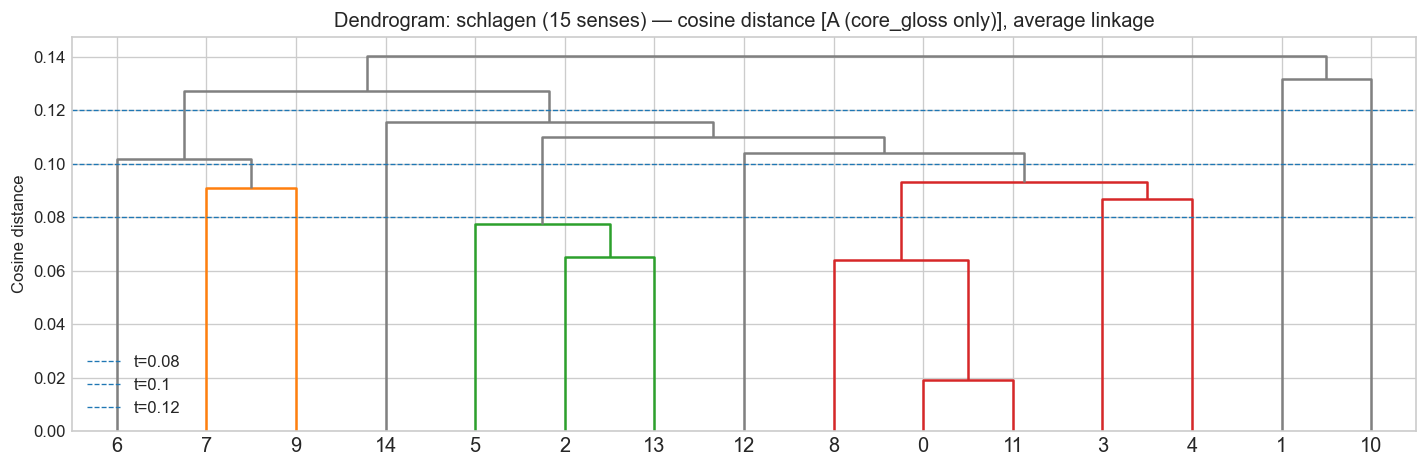

In [21]:
dist_matrix = cosine_distance_matrix(lemma_embs)
condensed = squareform(dist_matrix, checks=False)
Z = linkage(condensed, method='average')

labels = [str(i) for i in range(len(sense_ids))]

fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(Z, labels=labels, ax=ax, color_threshold=0.10, above_threshold_color='grey')

for t in THRESHOLDS:
    ax.axhline(t, linestyle='--', linewidth=0.8, label=f't={t}')

ax.legend()
ax.set_title(f'Dendrogram: {LEMMA} ({len(sense_ids)} senses) — cosine distance [{REPR_LABEL}], average linkage')
ax.set_ylabel('Cosine distance')
plt.tight_layout()
plt.show()

## 4. Cluster details across all thresholds

Shows how the sense inventory collapses for each lemma at each threshold. Look for a threshold where merges are semantically natural and singletons are linguistically justified.

In [22]:
for lemma in available_lemmas:
    mask = senses_df['lemma'] == lemma
    lemma_senses = senses_df[mask].reset_index(drop=True)
    lemma_embs = embeddings[mask.values]
    sids = lemma_senses['synset_id'].tolist()
    gloss_by_sid = dict(zip(sids, lemma_senses['core_gloss'].fillna('').tolist()))
    idx_by_sid = {sid: i for i, sid in enumerate(sids)}

    print(f"\n{'='*60}")
    print(f"{lemma} ({len(sids)} fine senses)  [{REPR_LABEL}]")

    for t in THRESHOLDS:
        mapping = cluster_senses_for_lemma(lemma_embs, sids, threshold=t)
        clusters = {}
        for sid, cid in mapping.items():
            clusters.setdefault(cid, []).append(sid)

        print(f"\n  t={t}: {len(sids)} → {len(clusters)} clusters")
        for cid, members in sorted(clusters.items()):
            print(f"    cluster {cid}:")
            for s in members:
                print(f"      [{idx_by_sid[s]:2d}] {s}  {gloss_by_sid[s]}")


schlagen (15 fine senses)  [A (core_gloss only)]

  t=0.08: 15 → 11 clusters
    cluster 0:
      [ 2] s56941  jemandem Schläge versetzen oder sich prügeln
      [ 5] s56930  jmdm./einem Tier einen Schlag/mehrere Schläge versetzen
      [13] s56641  jmdm. Schläge versetzen oder sich prügeln
    cluster 1:
      [ 0] s57717  Heftig gegen etwas fallen
      [ 8] s59100  mit etwas Heftigkeit einen Schlag ausführen
      [11] s58652  Mit Heftigkeit gegen etwas fallen
    cluster 2:
      [12] s56713  Sieg über einen Gegner erringen
    cluster 3:
      [10] s54197  Ritter durch Zeremonie ernennen oder auszeichnen
    cluster 4:
      [14] s54502  Flügel heftig und rasch auf und nieder bewegen
    cluster 5:
      [ 1] s52013  in Art und Wesen einem anderen Familienmitglied ähnlich sein
    cluster 6:
      [ 4] s56972  Mit einem Werkzeug oder Körperteil auf etwas einwirken
    cluster 7:
      [ 6] s123462  Sahne durch kräftiges Rühren aufschlagen
    cluster 8:
      [ 9] s53591  Trommel

## 5. Intra-cluster similarity stats

Quantitative summary. `mean_intra_cluster_similarity` confirms merged senses are genuinely close; `min_intra_cluster_similarity` flags forced merges. `constrained=True` means the min/max constraint overrode the organic threshold result. `reduction_ratio` = 1 − (n_coarse / n_fine).

In [23]:
def compute_intra_cluster_similarities(embs, mapping):
    """Compute mean/min intra-cluster cosine similarity."""
    sim = embs @ embs.T
    cluster_ids = sorted(set(mapping.values()))
    sense_ids_ordered = list(mapping.keys())

    sims = []
    for cid in cluster_ids:
        members_idx = [i for i, sid in enumerate(sense_ids_ordered) if mapping[sid] == cid]
        if len(members_idx) < 2:
            continue
        intra = [sim[i, j] for ii, i in enumerate(members_idx) for j in members_idx[ii+1:]]
        sims.extend(intra)

    if not sims:
        return float('nan'), float('nan')
    return np.mean(sims), np.min(sims)


def organic_cluster_count(embs, threshold):
    """Cluster count from threshold alone, no min/max constraint."""
    dist_matrix = cosine_distance_matrix(embs)
    model = AgglomerativeClustering(
        n_clusters=None, distance_threshold=threshold,
        metric='precomputed', linkage='average',
    )
    return len(set(model.fit_predict(dist_matrix)))


rows = []
for lemma in available_lemmas:
    mask = senses_df['lemma'] == lemma
    lemma_embs = embeddings[mask.values]
    sids = senses_df[mask]['synset_id'].tolist()

    for t in THRESHOLDS:
        mapping = cluster_senses_for_lemma(lemma_embs, sids, threshold=t)
        clusters = {}
        for sid, cid in mapping.items():
            clusters.setdefault(cid, []).append(sid)

        n_fine = len(sids)
        n_coarse = len(clusters)
        n_organic = organic_cluster_count(lemma_embs, t)
        n_singleton = sum(1 for m in clusters.values() if len(m) == 1)
        max_size = max(len(m) for m in clusters.values())
        mean_sim, min_sim = compute_intra_cluster_similarities(lemma_embs, mapping)

        rows.append({
            'lemma': lemma,
            'threshold': t,
            'n_fine_senses': n_fine,
            'n_organic_clusters': n_organic,
            'n_coarse_clusters': n_coarse,
            'constrained': n_organic != n_coarse,
            'n_singleton_clusters': n_singleton,
            'reduction_ratio': round(1 - n_coarse / n_fine, 3),
            'mean_intra_cluster_similarity': round(mean_sim, 3) if not np.isnan(mean_sim) else None,
            'min_intra_cluster_similarity': round(min_sim, 3) if not np.isnan(min_sim) else None,
            'max_cluster_size': max_size,
        })

summary_df = pd.DataFrame(rows)
summary_df

,lemma,threshold,n_fine_senses,n_organic_clusters,n_coarse_clusters,constrained,n_singleton_clusters,reduction_ratio,mean_intra_cluster_similarity,min_intra_cluster_similarity,max_cluster_size
0,schlagen,0.08,15,11,11,False,9,0.267,0.939,0.918,3
1,schlagen,0.10,15,8,8,False,5,0.467,0.921,0.899,5
2,schlagen,0.12,15,4,4,False,2,0.733,0.899,0.860,10
3,Geist,0.08,6,3,3,False,1,0.500,0.980,0.967,3
4,Geist,0.10,6,3,3,False,1,0.500,0.980,0.967,3
5,Geist,0.12,6,3,3,False,1,0.500,0.980,0.967,3
6,spielen,0.08,15,10,10,False,6,0.333,0.932,0.911,3
7,spielen,0.10,15,8,8,False,4,0.467,0.919,0.895,5
8,spielen,0.12,15,3,3,False,1,0.800,0.893,0.843,12
9,Berg,0.08,2,1,2,True,2,0.000,NaN,NaN,1


## 6. Lower threshold sweep

Sweeps thresholds without min/max constraints to find where organic splits first appear. Use this to recalibrate THRESHOLDS at the top of the notebook.

Previously (Original representation): organic splits appeared at t=0.14–0.18. With A (core_gloss only), distances are lower (max ~0.17) so the meaningful range is expected to shift down.

In [24]:
LOW_THRESHOLDS = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18]

print(f"{'lemma':<12}", end="")
for t in LOW_THRESHOLDS:
    print(f"  t={t:.2f}", end="")
print()
print("-" * (12 + 9 * len(LOW_THRESHOLDS)))

for lemma in available_lemmas:
    mask = senses_df['lemma'] == lemma
    embs = embeddings[mask.values]
    sids = senses_df[mask]['synset_id'].tolist()
    n = len(sids)

    print(f"{lemma:<12}", end="")
    for t in LOW_THRESHOLDS:
        dist_matrix = cosine_distance_matrix(embs)
        model = AgglomerativeClustering(
            n_clusters=None, distance_threshold=t,
            metric='precomputed', linkage='average',
        )
        labels = model.fit_predict(dist_matrix)
        n_clusters = len(set(labels))
        marker = " *" if n_clusters > 1 else "  "
        print(f"{marker}{n_clusters:>3}/{n:<3}", end="")
    print()

print(f"\n[{REPR_LABEL}] * = organic split (no constraint applied)")

lemma         t=0.02  t=0.04  t=0.06  t=0.08  t=0.10  t=0.12  t=0.14  t=0.16  t=0.18
---------------------------------------------------------------------------------------------
schlagen     * 14/15  * 14/15  * 14/15  * 11/15  *  8/15  *  4/15  *  2/15     1/15     1/15 
Geist        *  4/6   *  3/6   *  3/6   *  3/6   *  3/6   *  3/6      1/6      1/6      1/6  
spielen      * 15/15  * 15/15  * 14/15  * 10/15  *  8/15  *  3/15     1/15     1/15     1/15 
Berg            1/2      1/2      1/2      1/2      1/2      1/2      1/2      1/2      1/2  
Kugel        *  3/3   *  2/3   *  2/3   *  2/3   *  2/3   *  2/3   *  2/3      1/3      1/3  
Kopf         *  7/8   *  6/8   *  6/8   *  6/8   *  5/8   *  3/8   *  2/8      1/8      1/8  
sprechen     *  5/6   *  4/6   *  2/6   *  2/6      1/6      1/6      1/6      1/6      1/6  
tief         *  6/6   *  5/6   *  4/6   *  3/6   *  2/6      1/6      1/6      1/6      1/6  
gehen        * 19/19  * 19/19  * 18/19  * 17/19  * 14/19  *  7/19  * 

## Notes

**Representation comparison result (2026-03-12):**

| Representation | Distance range | max/min ratio | Verdict |
|---|---|---|---|
| Original (llm_def+ex) | 0.13–0.22 | ~1.7× | Boilerplate compresses distances |
| A (core_gloss only) | 0.04–0.18 | ~5× | **Winner** — widest relative spread |
| B (core_gloss+ex) | 0.02–0.11 | ~7× | Worst — examples dominate and compress everything |

**Why B is unexpectedly bad**: all 5 examples for a lemma share its vocabulary regardless of which sense they illustrate, pulling all sense embeddings toward the same lemma centroid. Short core_gloss can't counteract it.

**Selected representation: A (core_gloss only)**

---

**Threshold decision: t=0.10 — confirmed across 10 words (2026-03-14)**

After full core_gloss re-generation (improved prompt: sibling context, POS norms, concreteness rules), organic cluster counts increased substantially. t=0.10 remains the right threshold — it produces the first organic splits at a linguistically meaningful granularity.

| Lemma | n senses | organic clusters at t=0.10 | coarse clusters | notes |
|---|---|---|---|---|
| schlagen | 15 | 8 | 8 (organic ✓) | linguistically coherent; one misassignment (s56713) |
| spielen | 15 | 8 | 8 (organic ✓) | color/light senses correctly separated after manual patches |
| Geist | 8 | 3 | 3 (organic ✓) | supernatural / mental / Branntwein |
| gehen | 19 | 14 | 14 (organic ✓) | many fine senses; sparse clusters filtered at analysis time |
| fassen | 12 | 6 | 6 (organic ✓) | largely coherent |

**t=0.10 rationale (updated):**
- Threshold produces first organic splits for nearly all test words
- No upper bound on cluster count — t=0.10 determines granularity organically
- Sparse word-decade cells (low n) filtered at analysis time, not pre-emptively merged
- Geist and fassen cluster fully organically — singleton outliers are genuine
- gehen's 14 organic clusters are accepted; very sparse gehen-clusters will be filtered at analysis stage

**Core gloss quality review (2026-03-14):**

Systematic over-abstraction was identified: many glosses lost sense-specific nouns and collapsed into generic phrases (e.g. "mit etwas eine Handlung ausführen"). Root cause: sibling context instruction pushed toward abstract differentiation; prompt examples taught wrong patterns.

Fix: Prompt refined to 6 rules — enforce concreteness, POS-appropriate phrase type, and preserve key nouns from baseline. Sibling block relabeled "nur zur Orientierung — nicht aufzählen".

Three manual patches applied (regressions after re-generation):
- `s52049` (gehen): → "akzeptabel sein oder gerade noch funktionieren"
- `s58716` (spielen): → "Farben und Facetten reflektieren"
- `s58405` (spielen): → "Licht auf einer Oberfläche reflektieren"

---

**Next step:** Run `scripts/compute_sense_clusters.py` at t=0.10 on all 90 pilot words.